---
 
<span style="color: #000000; font-family: Lucida Console; font-size: 2em;">
<b>Tutorial de python (programación avanzada, tutorial en construcción)</b>
</span>
 
---

# Objetos

Un objeto es un tipo de dato que contiene varios datos (similar a las estructuras), pero que
además define funciones.
Para su creación se usan funciones llamdas constructores y a veces para
eliminarlos usamos destructores.


## Ejemplo 1: ideales de los números enteros

Para ilustrar este concepto pensemos en los ideales de $\mathbb Z$. Algunas de las operaciones y propiedades de estos conjuntos son las siguientes:
* Para todo subconjunto de $\mathbb Z$, existe el ideal más pequeño que lo contiene. Esto hace que a partir de cualquier subconjunto de enteros podemos crear un ideal.
* La intersección de ideales es un ideal. 
* La suma de dos ideales es el ideal más pequeño que contiene a la unión de ambos.
* Para todo ideal existe un número natural que lo genera.

Vamos a crear ahora la clase `IdealZ` para operar con estos conjuntos.

In [1]:
class C1:
    def __init__(self,x):
        self.X=x
        self.Y=2*x
    def printX(self):
        print(self.X)

In [2]:
objC1=C1(7)

In [3]:
objC1.printX()

7


In [4]:
from functools import reduce
from math import gcd
class IdealZ:
    '''
    Clase para representar ideales del conjunto 
    de los enteros
    '''
    def __init__(self, listaGeneradores ): 
        # Crea el ideal más pequeño que 
        # contiene a listaGeneradores
        if type(listaGeneradores)==list and len(listaGeneradores)>0:
            self.lGen=listaGeneradores
            self.generador=reduce(gcd, listaGeneradores)
            if self.generador<0:
                self.generador=-self.generador
        elif type(listaGeneradores)==int:
            self.generador=listaGeneradores
        else:
            print('No se puede crear el ideal',type(listaGeneradores)==list)
            
    def __str__(self):
        # Muestra información del ideal
        return '<'+str( self.generador )+'>'
    def __eq__(self, otroIdeal):
        # Compara dos ideales. Esta función hace que podamos usar
        # el == y el != con el tipo de dato IdealZ
        return self.generador==otroIdeal.generador
    def suma(self, otroIdeal):
        return IdealZ( gcd(self.generador,otroIdeal.generador ) )
    def interseccion(self,otroIdeal):
        a,b=otroIdeal.generador,self.generador
        aux=a*b//gcd(a,b)
        return IdealZ( aux )
    def generador(self):
        return self.generador

In [5]:
I1=IdealZ([12,18])

In [6]:
I1.generador()

TypeError: 'int' object is not callable

In [7]:
i1=IdealZ([12,18])
i2=IdealZ([30,60])
print(i1,i2,i1==i2,i1.suma(i2),i1.interseccion(i2))
print(IdealZ(5).interseccion( IdealZ(7) ))

<6> <30> False <6> <30>
<35>


## Ejemplo 2: Menú de aplicación

Muchas veces al hacer un programa nos encontramos que tenemos que realizar menús con opciones y al elegir una de sus opciones tenemos que realizar esa tarea de nuevo. Utilizando la clase `Menu` podemos ahorrarnos líneas en nuestro programa.

In [8]:
class Menu:
    def __init__(self,listaOpc):
        self.listaOpciones=listaOpc
        self.funcionesALlamar={}
        self.opcionElegida=-1
    def pinta(self):
        for i in range(len(self.listaOpciones)):
            print( "%3s.- %40s" % (str(i+1),self.listaOpciones[i]) )
    def pideOpcionYLlama(self):
        self.opcionElegida=input("Introduzca opcion: ")
        op=int(self.opcionElegida)
        lk=list(self.funcionesALlamar.keys())
        if lk.count(op)>0:
            self.funcionesALlamar[op]()
    def asignaFunciones(self,dictFunc):
        self.funcionesALlamar=dictFunc
    def __str__(self):
        cad='Opciones:'+str(self.listaOpciones)+'\n'
        cad=cad+'Opcion elegida:'+str(self.opcionElegida)+'\n'
        cad=cad+'Opciones:'+str(self.funcionesALlamar.keys())
        return cad

In [9]:
def f1():
    print( 'funcion f1' )
def f2():
    print( 'funcion f2' )
    
m=Menu(["opcion 1","opcion 2"])
m.pinta()
m.asignaFunciones({1:f1,2:f2})
m.pideOpcionYLlama()
print( m )

  1.-                                 opcion 1
  2.-                                 opcion 2
Introduzca opcion: 234
Opciones:['opcion 1', 'opcion 2']
Opcion elegida:234
Opciones:dict_keys([1, 2])


## Ejemplo 3: Coche y furgoneta con herencia

Construimos el tipo de dato `Coche`

In [85]:
class Coche:
	"""Definición del objeto coche"""
	def __init__(self,gasolina): # este es el constructor
		self.gasolina=gasolina
		print("Tenemos",gasolina,"litros")
		
	def arrancar(self): # todas las funciones tiene al menos el argumento self
		if self.gasolina>0:
			print("Arranca")
		else:
			print("No arranca")
	def conducir(self):
		if self.gasolina>0:
			self.gasolina-=1
			print("Quedan",self.gasolina,"litros")
		else:
			print("No se mueve")
	def __str__(self):
		return "Gasolina del coche: "+str(self.gasolina)

Veamos como funciona.

In [86]:
mi_coche=Coche(3) # construimos un dato de tipo Coche
print(mi_coche.gasolina)
print(mi_coche)
mi_coche.arrancar()
mi_coche.conducir()

Tenemos 3 litros
3
Gasolina del coche: 3
Arranca
Quedan 2 litros


Podemos construir nuevos tipos de objetos a partir de otros tipos ya existentes (herencia).

In [87]:
class Furgoneta(Coche):
	'''Clase derivada de Coche'''
	def __init__(self,gasolina,carga):
		Coche.__init__(self,gasolina)
		self.carga=carga
		print("gasolina:",gasolina,"carga:",carga)
	def __funcionprivada(self):
		return self.gasolina-self.carga
	def eficiencia(self):
		print( self.__funcionprivada() )
	def __str__(self):
		return "Gasolina de la furgoneta: "+str(self.gasolina)+" : Carga:"+str(self.carga)
	def __cmp__(self,otro):
		return (self.gasolina-self.carga)-(otro.gasolina-otro.carga)

Veamos como funciona

In [89]:
help(Furgoneta)
mi_furgoneta=Furgoneta(5,10)
mi_furgoneta.eficiencia()
mf1=Furgoneta(5,10)
mf2=Furgoneta(15,22)
print( mi_furgoneta == mf1 , mf2 == mf1 )
print( mi_furgoneta )
print( mf1 )
print( mf2 )

Help on class Furgoneta in module __main__:

class Furgoneta(Coche)
 |  Clase derivada de Coche
 |  
 |  Method resolution order:
 |      Furgoneta
 |      Coche
 |      builtins.object
 |  
 |  Methods defined here:
 |  
 |  __cmp__(self, otro)
 |  
 |  __init__(self, gasolina, carga)
 |      Initialize self.  See help(type(self)) for accurate signature.
 |  
 |  __str__(self)
 |      Return str(self).
 |  
 |  eficiencia(self)
 |  
 |  ----------------------------------------------------------------------
 |  Methods inherited from Coche:
 |  
 |  arrancar(self)
 |  
 |  conducir(self)
 |  
 |  ----------------------------------------------------------------------
 |  Data descriptors inherited from Coche:
 |  
 |  __dict__
 |      dictionary for instance variables (if defined)
 |  
 |  __weakref__
 |      list of weak references to the object (if defined)

Tenemos 5 litros
gasolina: 5 carga: 10
-5
Tenemos 5 litros
gasolina: 5 carga: 10
Tenemos 15 litros
gasolina: 15 carga: 22
False 

# Excepciones

Son errores detectados durante la ejecución de un programa com por ejemplo cuando se ejecuta 
`int('a')` o `5/0`.

In [132]:
int('a')

ValueError: invalid literal for int() with base 10: 'a'

In [136]:
x='5'
try:
    int(x)
    print(5/0)
    print('Conversión realizada')
except ValueError as e:
    print('Hay un error del tipo ValueError:',e)
except ZeroDivisionError as e:
    print('Hay un error del tipo ZeroDivisionError', e)

Hay un error del tipo ZeroDivisionError division by zero


In [170]:
5/0

ZeroDivisionError: division by zero

La estructura para capturar cualquier tipo de excepción es la siguiente:
<pre>
try:
	f=file("aaa.txt")
except:
	print "Error..."
</pre>

Podemos realizar un tratamiento diferenciado según el tipo de excepción. Por ejemplo para
las excepciones
<code>NameError</code> y <code>ValueError</code>:

In [137]:
try:
    num=int(var1)
except NameError:
    print("La variable no existe")
except ValueError:
    print("El valor no es un numero")

La variable no existe


Otro ejemplo de tratamiento diferenciado

In [138]:
var1='aa'
try:
    num=int(var1)
except NameError as e:
    print("La variable no existe")
    print(e)
except ValueError as e:
    print("El valor no es un numero")
    print(e)

El valor no es un numero
invalid literal for int() with base 10: 'aa'


O podemos tratar de igual forma varios tipos de excepciones:

In [140]:
try:
    num=int(var1)
except (NameError,ValueError) as e:
    print("La variable no existe o no es un número")
    print(e)
except ZeroDivisionError:
    print("El valor no es un numero")

La variable no existe o no es un número
invalid literal for int() with base 10: 'aa'


In [142]:
try:
    print(5/0)
except NameError as e:
    print('NameError:',e)
except ZeroDivisionError as e:
    print('ZeroDivisionError:',e)
except Exception as e:
    print('Exception:',e)

ZeroDivisionError: division by zero


In [149]:
try:
    num=33
    #print(1/0)
except Exception as e:
    print( "Hubo error", e )
else:
    print( "Dentro del else" )
finally:
    print('Dentro del finally')

Dentro del else
Dentro del finally


* El `finally` siempre se ejecuta
* El `else` se ejecuta si salimos por el try

El finally es una zona que código que se ejecuta siempre:

In [178]:
try:
    z=x/y
except ZeroDivisionError:
    print( "División por cero" )
except Exception as e:
    print( "Otro tipo de error:" )
    print(e)
finally:
    print( "Limpiando" )

Otro tipo de error:
name 'x' is not defined
Limpiando


Un tipo de error muy común es intentar acceder a una posición de una lista que no existe.

In [179]:
try:
    range(10)[20]
except IndexError as e:
    print(e)

range object index out of range


Son frecuentes los errores al abrir un fichero:

In [150]:
try:
    f1=open('kkk','r')
except IOError as ee:
    print('IOError',type(ee),ee)
except Exception as e:
    print('Otro tipo',e)

IOError <class 'FileNotFoundError'> [Errno 2] No such file or directory: 'kkk'


También son frecuentes los errores a intentar conectarnos con alguna
dirección web.

In [152]:
from urllib.request import urlopen
from urllib.error import URLError

try:
    f=urlopen('http://aaagoogle.es')
    cad=f.read()
    f.close()
except URLError as e:
    print('Error al conectar')

Error al conectar


En definitiva, el try debe usarse siempre que exista algún riesgo de que el programa
tenga un error en tiempo de ejecución por factores externos
(leer un fichero, acceder a página web, convertir una cadena a número, acceder a una posición
de la lista sys.argv, etc...).
No es necesario su uso para acceder a la posición 0 de una lista que acabamos de crear.

## Definición de excepciones

Definimos la clase MiError:

In [186]:
class MiError(Exception):
    def __init__(self,valor):
        self.valor=valor
    def __str__(self):
        return "Error "+str(self.valor)

Ejecutamos ahora

In [187]:
resultado=10
try:
    if resultado>20:
        raise MiError(33)
except MiError as e:
    print(e)
else:
    print("sin errores, resultado=",resultado)

sin errores, resultado= 10


Cambiamos el valor de resultado. En este caso la excepción es lanzada.

In [ ]:
resultado=30
try:
    if resultado>20:
        raise MiError(33)
except MiError as e:
    print(e)
else:
    print("sin errores, resultado=",resultado)

# Matplolib

Matplotlib es la librería de python más usada para visualizar gráficos en 2D.
Dentro de matplotlib tenemos a pyplot que nos va a proporcionar un acceso orientado a objetos
a matplotlib.
Para pintar nuestras gráficas haremos uso de algunas de la funciones de la librería numpy.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import interactive
# %matplotlib inline
%matplotlib notebook

<IPython.core.display.Javascript object>


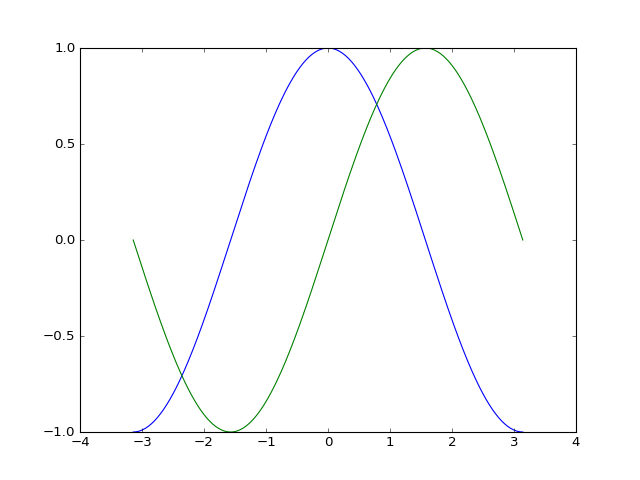

In [11]:
#Creamos la ventana
plt.subplot(1,1,1)

#Creamos una lista de valores entre -Pi y Pi
X=np.linspace(-np.pi,np.pi,256,endpoint=True)

#Calculamos el coseno y el seno a esos valores
C,S=np.cos(X),np.sin(X)

#Pintamos las gráficas:
plt.plot(X,C)
plt.plot(X,S)

#Las mostramos:
interactive(True)
plt.show()

Podemos tener más control de lo que aparece en la ventana.
Vamos a crear una figura de tamaño concreto con la orden plt.figure

<IPython.core.display.Javascript object>


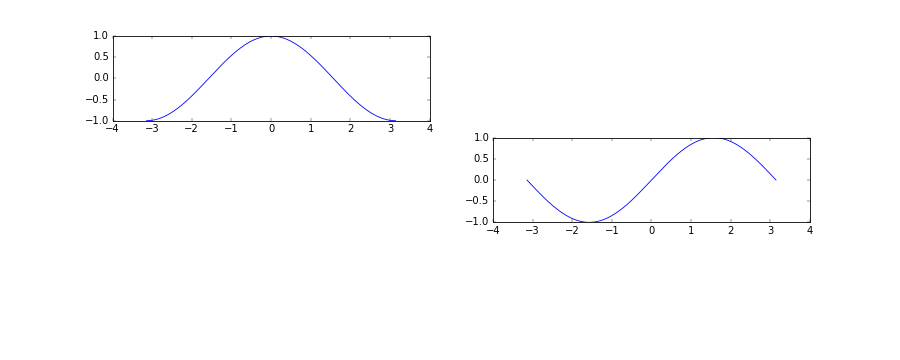

In [12]:
plt.figure(figsize=(15,6), dpi=60)

#Creamos una ventana (la número 1) de tamaño 1x1
plt.subplot(1,1,1)

#Definimos X, C, S como antes:
X = np.linspace(-np.pi, np.pi, 256,endpoint=True)
C,S = np.cos(X), np.sin(X)

#Pintamos de color azul y verde, y añadimos una leyenda:
plt.plot(X, C, color="blue", linewidth=1.0, linestyle="-",label='Coseno')
plt.plot(X, S, color="red", linewidth=2.0, linestyle="-",label='Seno')
plt.legend(loc='upper left',frameon=True)

#Añadimos anotaciones a puntos
plt.scatter(0,1,c='r',marker='2',linewidth=10)
plt.annotate('nota',xy=(0,1),arrowprops=dict(arrowstyle="->"),xytext=(+10, +30), textcoords='offset points')

#Establecemos los límites de x e y, y las marcas en los ejes:
plt.xlim(-3.0,4.0)
plt.xticks(np.linspace(-4,4,9,endpoint=True))
plt.ylim(-1.5,1.5)
plt.yticks(np.linspace(-1,1,9,endpoint=True))

#grabamos la figura:
plt.savefig("grafica.png",dpi=72)

#Mostramos la ventana
plt.show()

Podemos crear ventanas con varias gráficas a la vez.

In [13]:
plt.subplot(2,1,1)
plt.plot(X,C)
plt.subplot(2,1,2)
plt.plot(X,S)
plt.show()

In [14]:
plt.subplot(3,2,1)
plt.plot(X,C)
plt.subplot(3,2,4)
plt.plot(X,S)
plt.show()

También podemos mover las gráficas.

<IPython.core.display.Javascript object>


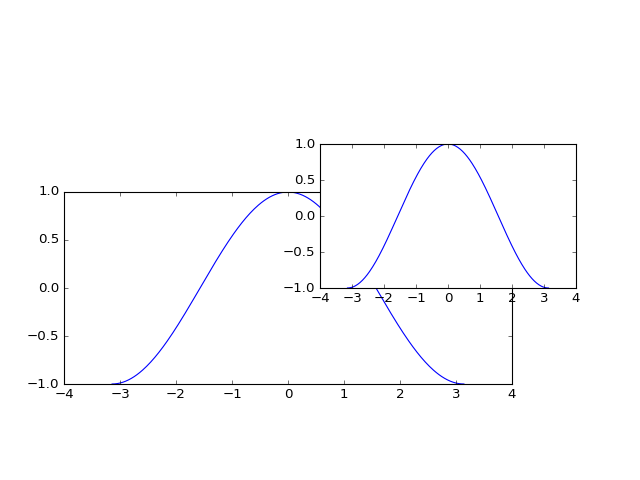

In [129]:
plt.axes([.1,.2,.7,.4])
plt.plot(X,C)
plt.axes([.5,.4,.4,.3])
plt.plot(X,C)
plt.show()

Gráficas de barras y puntos.

<IPython.core.display.Javascript object>


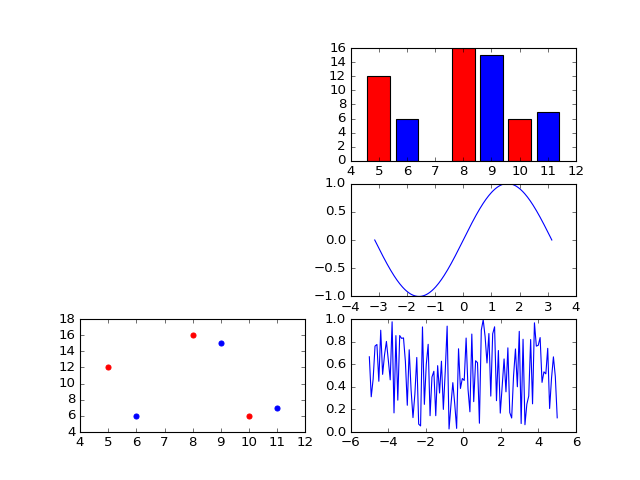

In [130]:
# Estructura de un programa y llamadas a librerías
plt.plot(X,C)
plt.subplot(3,2,4)
plt.plot(X,S)
plt.subplot(3,2,2)
plt.bar([5,8,10],[12,16,6],color='r',align='center')
plt.bar([6,9,11],[6,15,7],color='b',align='center')
plt.subplot(3,2,5)
plt.scatter([5,8,10],[12,16,6],color='r')
plt.scatter([6,9,11],[6,15,7],color='b')
plt.subplot(3,2,6)
import random
plt.plot(np.linspace(-5, 5, 100),[random.random() for i in range(100)])
plt.show()

# Estructura de un programa y llamadas a librerías

## Estructura

La llamada a un programa puede realizarse desde el `WinPython Command Prompt` de la forma:
<pre>
C:\directorio> python programa.py
</pre>
Lo anterior leera el fichero desde el principio hasta el final e irá ejecutando todas las órdenes que encuentre (las pegadas al margen izquierdo del fichero). 
Es por ello que la estructura de un programa es conveniente que la hagamos de la siguiente forma:
<pre>
importamos las librerías necesarias con `import` o con `from librería import ...`

import os, urllib
from sys import argv
...
definición de funciones
...

def main():
    ...
    llamadas a funciones definidas en el fichero o de las librerías importadas
    ...

if __name__=='__main__':
    main()
</pre>

Se tiene que en los notebook el valor de `__name__` es `__main__`

In [227]:
print(__name__)

__main__


Es por ello que lo siguiente se comporta de igual forma a como lo haría una llamada desde el `WinPython Command Prompt` con la orden `python fichero.py` a un fichero `fichero.py` con el contenido que sigue.

In [229]:
import os
from sys import argv

def f(saludo):
    print(saludo, os.getcwd())
    
def g(saludo):
    print(saludo, argv)

def main():
    f('Hola!')
    g('Hola de nuevo.')

if __name__=='__main__':
    main()

Hola! /mnt/disco1TB/Dropbox/Asignaturas/FMSDD/FMSDD-curso20162017
Hola de nuevo. ['/usr/local/lib/python3.5/dist-packages/ipykernel/__main__.py', '-f', '/run/user/1000/jupyter/kernel-ad2e3742-8eb4-4653-a569-dcedb123933f.json']


## Llamadas a librerías

Las llamadas se hacen de la forma 
* `import librería1, librería2, ...`: Las funciones de librería1 y librería2 se llaman de la forma `librería1.func1`.
* `import librería as lb`: Es como el anterior pero tenemos que poner `lb` en lugar de `librería`.
* `from librería import funcion1, funcion2,...`: De esta forma podemos llamar directamente a `funcion1` y `funcion2` si tener que poner delante `librería.`.
* `from librería import *`: Hace que todas las funciones de `librería` se puedan llamar directamente.

Algunos ejemplos:

In [230]:
import os
print(os.get_exec_path())

['/home/jigg/bin', '/usr/local/sbin', '/usr/local/bin', '/usr/sbin', '/usr/bin', '/sbin', '/bin', '/usr/games', '/usr/local/games', '/snap/bin', '/home/jigg/bin', '/home/jigg/bin']


In [199]:
from os import getcwd, listdir
print(getcwd())
print(listdir())

/mnt/disco1TB/Dropbox/Asignaturas/FMSDD/FMSDD-curso20162017
['opencv-python-tutorial.ipynb', 'ficheroBinario.bin', 'ExtraccionDatosTablasHTML.ipynb', 'TutorialDePython.py', 'factorial.py', 'nuevo.ipynb', 'cc1.txt', 'opencv-python-tutorial.py', 'imgs', 'prueba1 (Copia en conflicto de i7Dell 2016-11-08).py', 'ipython_notebook_config.py', 'TutorialDePython.ipynb', 'prueba1.py', '.ipynb_checkpoints', 'arranca.sh', 'mycert.pem', 'Jupyter Notebook Viewer.url', 'ficheroPrueba1.txt', 'beach-164288_1280.jpg']


In [238]:
from sympy import symbols, Matrix, pprint
x,y,z=symbols('x y z')
listaVariables=symbols('a1 a2 a3 a4')
pprint( x**2 + x*y +7)
pprint( listaVariables )
print()
pprint(Matrix([[1,2,3],[3,4,5]]))

 2          
x  + x⋅y + 7
(a₁, a₂, a₃, a₄)

⎡1  2  3⎤
⎢       ⎥
⎣3  4  5⎦


Por último, los ficheros `.py` del directorio donde estemos pueden también importarse.

In [16]:
import factorial # importamos el fichero factorial.py que contiene las funciones fact y cuadrado

ImportError: No module named 'factorial'

In [15]:
factorial.fact(5)

NameError: name 'factorial' is not defined

# Hebras

<img src='https://www.dropbox.com/s/6ql7e1n6c8arkg2/Website-Under-Construction.jpg?raw=1' width=200px>

# matplotlib

<img src='https://www.dropbox.com/s/6ql7e1n6c8arkg2/Website-Under-Construction.jpg?raw=1' width=200px>

# sqlite3 y SQL

<img src='https://www.dropbox.com/s/6ql7e1n6c8arkg2/Website-Under-Construction.jpg?raw=1' width=200px>

## sqlite3

<img src='https://www.dropbox.com/s/6ql7e1n6c8arkg2/Website-Under-Construction.jpg?raw=1' width=200px>

## SQL

<img src='https://www.dropbox.com/s/6ql7e1n6c8arkg2/Website-Under-Construction.jpg?raw=1' width=200px>

<img src='https://www.dropbox.com/s/6ql7e1n6c8arkg2/Website-Under-Construction.jpg?raw=1' width=200px>

# numpy

<img src='https://www.dropbox.com/s/6ql7e1n6c8arkg2/Website-Under-Construction.jpg?raw=1' width=200px>

# sklearn

<img src='https://www.dropbox.com/s/6ql7e1n6c8arkg2/Website-Under-Construction.jpg?raw=1' width=200px>